# Laboratorio de Aprendizaje Automático - Parte 1

## Inteligencia Artificial - DCIC, UNS (2026)

En este laboratorio aprenderemos conceptos y herramientas para el desarrollo de un proyecto con técnicas de aprendizaje automático. Veremos algunas nociones para el preprocesamiento de datos, junto con la construcción, entrenamiento y generación de predicciones utilizando dos métodos de aprendizaje automático: Árboles de Decisión (AD) y Redes Neuronales Artificiales (RNA).

**Recuerde hacer una copia de este notebook en su drive**.

## Plan de Trabajo

En esta primera parte, nos enfocaremos en los siguientes aspectos.

*   Importar un dataset, visualizar y analizar detalles del mismo.
*   Preprocesamiento de datos:
    * Procesamiento de columnas con valores nulos.
    * Modificaciones de columnas con variables categóricas.
    * Normalización/estandarización de los datos.

En las próximas partes nos centraremos en:

*   Desarrollar modelos de clasificación:
    * Construir un Árbol de Decisión.
    * Definir la estructura y entrenamiento de una RNA.
* Evaluar los modelos desarrollados.
*   Generar predicciones sobre nuevos datos.

## Datasets

En el laboratorio vamos a utilizar tres conjuntos de datos, que pueden **descargar ejecutando la primera celda de código** o desde el siguiente enlace: [datasets](https://drive.google.com/file/d/16AB3ixX9q2S7fHAbiE7id7zj1fCgPbo4/view?usp=drive_link).

*   Titanic dataset (titanic.csv)
*   Dataset precio celulares (cellphones.csv)
*   Dataset géneros musicales (music.csv)

## Librerías

A lo largo del laboratorio se usan principalmente tres librerías:
-   **Pandas**: Permite utilizar y analizar los datos. Link: https://pandas.pydata.org/docs/
 -  **Scikit-learn**: Permite manipular los datos e implementar diversos algoritmos de *Machine Learning*. Link: https://scikit-learn.org/stable/
 -  **Keras**: Permite implementar Redes Neuronales Artificiales de manera intuitiva. Link: https://keras.io/getting_started/

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import Sequential, layers, Input

!pip install -q gdown
!gdown --fuzzy "https://drive.google.com/file/d/16AB3ixX9q2S7fHAbiE7id7zj1fCgPbo4/view" -O /content/datasets_laboratorio.zip
!unzip /content/datasets_laboratorio.zip -d /content/

Downloading...
From: https://drive.google.com/uc?id=16AB3ixX9q2S7fHAbiE7id7zj1fCgPbo4
To: /content/datasets_laboratorio.zip
100% 155k/155k [00:00<00:00, 125MB/s]
Archive:  /content/datasets_laboratorio.zip
  inflating: /content/music.csv      
  inflating: /content/titanic.csv    
  inflating: /content/cellphones.csv  


## Carga de Datos y Visualización

En el siguiente bloque de código se realizan las siguientes tareas:
*   Importar el dataset. El dataset se importa como una tabla de datos en *pandas*, que se denomina **Dataframe**.
*   Obtener el número de filas y columnas del mismo (utilizando su propiedad *shape*).
*   Obtener el nombre de las columnas en la tabla (utilizando la propiedad *columns*).
*   Listar los primeros 10 elementos del dataset (utilizando la función *head*).

**Links**:
* `https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html`
* `https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html`



In [ ]:
# Cargar el dataset.
df_titanic = pd.read_csv('/content/titanic.csv')
df_original = df_titanic.copy()

print("Cantidad de ejemplos: {} \nCantidad de columnas: {} \n".format(df_titanic.shape[0], df_titanic.shape[1]))

# Nombre de las columnas
print("Lista con las columnas del dataset: {} \n".format(list(df_titanic.columns)))

# Ver los primeros ejemplos del dataset.
df_titanic

Cantidad de ejemplos: 891 
Cantidad de columnas: 8 

Lista con las columnas del dataset: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'Ticket', 'Cabin', 'Embarked'] 



,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked
0,1,No,third,"Braund, Mr. Owen Harris",22.0,A/5 21171,NaN,Southampton
1,2,Yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,PC 17599,C85,Cherbourg
2,3,Yes,third,"Heikkinen, Miss. Laina",26.0,STON/O2. 3101282,NaN,Southampton
3,4,Yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,113803,C123,Southampton
4,5,No,third,"Allen, Mr. William Henry",35.0,373450,NaN,Southampton
...,...,...,...,...,...,...,...,...
886,887,No,second,"Montvila, Rev. Juozas",27.0,211536,NaN,Southampton
887,888,Yes,first,"Graham, Miss. Margaret Edith",19.0,112053,B42,Southampton
888,889,No,third,"Johnston, Miss. Catherine Helen ""Carrie""",NaN,W./C. 6607,NaN,Southampton
889,890,Yes,first,"Behr, Mr. Karl Howell",26.0,111369,C148,Cherbourg


### Filtrado

Las siguientes instrucciones permiten obtener diferentes porciones del dataset, siguiendo algún criterio para filtrar los datos.
*  En los primeros dos ejemplos se selecciona una cantidad fija de filas de la tabla.
*  En los restantes, se realizan filtros según valores específicos de atributos.

In [ ]:
# Ej1: primeras 10 filas del dataset
df_titanic.head(15)

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked
0,1,No,third,"Braund, Mr. Owen Harris",22.0,A/5 21171,NaN,Southampton
1,2,Yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,PC 17599,C85,Cherbourg
2,3,Yes,third,"Heikkinen, Miss. Laina",26.0,STON/O2. 3101282,NaN,Southampton
3,4,Yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,113803,C123,Southampton
4,5,No,third,"Allen, Mr. William Henry",35.0,373450,NaN,Southampton
5,6,No,third,"Moran, Mr. James",NaN,330877,NaN,Queenstown
6,7,No,first,"McCarthy, Mr. Timothy J",54.0,17463,E46,Southampton
7,8,No,third,"Palsson, Master. Gosta Leonard",2.0,349909,NaN,Southampton
8,9,Yes,third,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",27.0,347742,NaN,Southampton
9,10,Yes,second,"Nasser, Mrs. Nicholas (Adele Achem)",14.0,237736,NaN,Cherbourg


In [ ]:
# Ej2: 10 filas del dataset seleccionadas de forma aleatoria
df_titanic.sample(10)

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked
748,749,No,first,"Marvin, Mr. Daniel Warner",19.0,113773,D30,Southampton
549,550,Yes,second,"Davies, Master. John Morgan Jr",8.0,C.A. 33112,NaN,Southampton
187,188,Yes,first,"Romaine, Mr. Charles Hallace (""Mr C Rolmane"")",45.0,111428,NaN,Southampton
66,67,Yes,second,"Nye, Mrs. (Elizabeth Ramell)",29.0,C.A. 29395,F33,Southampton
592,593,No,third,"Elsbury, Mr. William James",47.0,A/5 3902,NaN,Southampton
484,485,Yes,first,"Bishop, Mr. Dickinson H",25.0,11967,B49,Cherbourg
444,445,Yes,third,"Johannesen-Bratthammer, Mr. Bernt",NaN,65306,NaN,Southampton
855,856,Yes,third,"Aks, Mrs. Sam (Leah Rosen)",18.0,392091,NaN,Southampton
878,879,No,third,"Laleff, Mr. Kristo",NaN,349217,NaN,Southampton
251,252,No,third,"Strom, Mrs. Wilhelm (Elna Matilda Persson)",29.0,347054,G6,Southampton


In [ ]:
# Ej3: filas con pasajeros con edad menor a 20 años
df_titanic.loc[(df_titanic['Age'] < 20)]

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked
7,8,No,third,"Palsson, Master. Gosta Leonard",2.0,349909,NaN,Southampton
9,10,Yes,second,"Nasser, Mrs. Nicholas (Adele Achem)",14.0,237736,NaN,Cherbourg
10,11,Yes,third,"Sandstrom, Miss. Marguerite Rut",4.0,PP 9549,G6,Southampton
14,15,No,third,"Vestrom, Miss. Hulda Amanda Adolfina",14.0,350406,NaN,Southampton
16,17,No,third,"Rice, Master. Eugene",2.0,382652,NaN,Queenstown
...,...,...,...,...,...,...,...,...
855,856,Yes,third,"Aks, Mrs. Sam (Leah Rosen)",18.0,392091,NaN,Southampton
869,870,Yes,third,"Johnson, Master. Harold Theodor",4.0,347742,NaN,Southampton
875,876,Yes,third,"Najib, Miss. Adele Kiamie ""Jane""",15.0,2667,NaN,Cherbourg
877,878,No,third,"Petroff, Mr. Nedelio",19.0,349212,NaN,Southampton


In [ ]:
# Ej4: filas con pasajeros que embarcaron en Queenstown o Southampton
df_titanic.loc[df_titanic['Embarked'].isin(['Queenstown', 'Southampton'])]

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked
0,1,No,third,"Braund, Mr. Owen Harris",22.0,A/5 21171,NaN,Southampton
2,3,Yes,third,"Heikkinen, Miss. Laina",26.0,STON/O2. 3101282,NaN,Southampton
3,4,Yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,113803,C123,Southampton
4,5,No,third,"Allen, Mr. William Henry",35.0,373450,NaN,Southampton
5,6,No,third,"Moran, Mr. James",NaN,330877,NaN,Queenstown
...,...,...,...,...,...,...,...,...
885,886,No,third,"Rice, Mrs. William (Margaret Norton)",39.0,382652,NaN,Queenstown
886,887,No,second,"Montvila, Rev. Juozas",27.0,211536,NaN,Southampton
887,888,Yes,first,"Graham, Miss. Margaret Edith",19.0,112053,B42,Southampton
888,889,No,third,"Johnston, Miss. Catherine Helen ""Carrie""",NaN,W./C. 6607,NaN,Southampton


In [ ]:
# Ej5: sección del dataset conteniendo solo el nombre de la persona y si sobrevivió.
df_titanic[['Name', 'Survived']]

,Name,Survived
0,"Braund, Mr. Owen Harris",No
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Yes
2,"Heikkinen, Miss. Laina",Yes
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Yes
4,"Allen, Mr. William Henry",No
...,...,...
886,"Montvila, Rev. Juozas",No
887,"Graham, Miss. Margaret Edith",Yes
888,"Johnston, Miss. Catherine Helen ""Carrie""",No
889,"Behr, Mr. Karl Howell",Yes


In [ ]:
# Ej6: sección del dataset conteniendo el nombre y la edad de los sobrevivientes que iban en primera clase.
df_titanic.loc[(df_titanic['Pclass'] == 'first') & (df_titanic['Survived'] == 'Yes')][['Name', 'Age']]

,Name,Age
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0
11,"Bonnell, Miss. Elizabeth",58.0
23,"Sloper, Mr. William Thompson",28.0
31,"Spencer, Mrs. William Augustus (Marie Eugenie)",NaN
...,...,...
862,"Swift, Mrs. Frederick Joel (Margaret Welles Ba...",48.0
871,"Beckwith, Mrs. Richard Leonard (Sallie Monypeny)",47.0
879,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",56.0
887,"Graham, Miss. Margaret Edith",19.0


In [ ]:
# Ej7: sección del dataset conteniendo el nombre, la edad y el valor de Survived para los pasajeros de Southampton menores a 20 años.

df_titanic.loc[(df_titanic['Embarked'] == 'Southampton') & (df_titanic['Age'] < 20)][['Name', 'Age', 'Survived']]

,Name,Age,Survived
7,"Palsson, Master. Gosta Leonard",2.0,No
10,"Sandstrom, Miss. Marguerite Rut",4.0,Yes
14,"Vestrom, Miss. Hulda Amanda Adolfina",14.0,No
24,"Palsson, Miss. Torborg Danira",8.0,No
27,"Fortune, Mr. Charles Alexander",19.0,No
...,...,...,...
853,"Lines, Miss. Mary Conover",16.0,Yes
855,"Aks, Mrs. Sam (Leah Rosen)",18.0,Yes
869,"Johnson, Master. Harold Theodor",4.0,Yes
877,"Petroff, Mr. Nedelio",19.0,No


### Análisis del dataset

En las siguientes celdas de código vamos a obtener más información acerca de los datos con los que estamos trabajando. En particular buscamos conocer:
*   Información acerca de cada columna del *dataframe*.
*   Información sobre la columna *target*.
*   Aquellas columnas que tiene **valores nulos**.
*   Aquellas columnas que son **categóricas**.

In [ ]:
# Vemos información básica sobre las columnas del dataset
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Age          714 non-null    float64
 5   Ticket       891 non-null    object 
 6   Cabin        204 non-null    object 
 7   Embarked     889 non-null    object 
dtypes: float64(1), int64(1), object(6)
memory usage: 55.8+ KB


Distribución de columna target (cantidad de ejemplos):
Survived
No     549
Yes    342
Name: count, dtype: int64


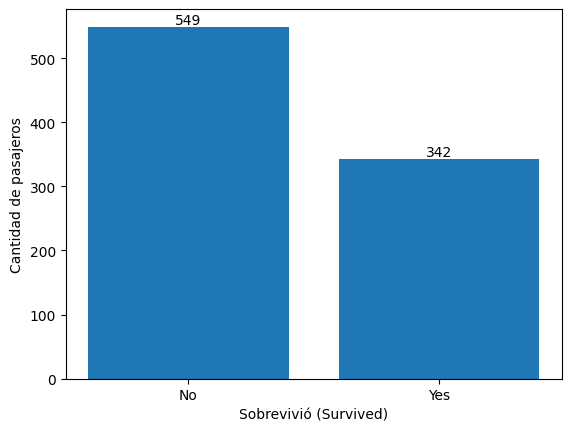

In [ ]:
# Distribución de los ejemplos (filas del dataset) para cada clase
print("Distribución de columna target (cantidad de ejemplos):")
survived_counts = df_titanic['Survived'].value_counts()
print(survived_counts)

# Crear el histograma
plt.bar(survived_counts.index, survived_counts.values)

# Agregar etiquetas de texto encima de cada columna
for i, count in enumerate(survived_counts.values):
    plt.text(i, count, str(count), ha='center', va='bottom')

# Agregar etiquetas y título
plt.xlabel('Sobrevivió (Survived)')
plt.ylabel('Cantidad de pasajeros')

# Mostrar el histograma
plt.show()

In [ ]:
# Columnas que tienen valores nulos
print("Columnas con valores nulos:")
for column in df_titanic.columns:
    cantidad_nulls = df_titanic[column].isna().sum()
    if cantidad_nulls > 0:
        print(f"-> La columna {column} contiene {cantidad_nulls} nulos.")

Columnas con valores nulos:
-> La columna Age contiene 177 nulos.
-> La columna Cabin contiene 687 nulos.
-> La columna Embarked contiene 2 nulos.


In [ ]:
# Información sobre columnas categóricas
print("Columnas categóricas:")
for column in df_titanic.columns:
    if df_titanic[column].dtype == 'object':
        values = df_titanic[column].unique()
        print(f"-> La columna {column} tiene {len(values)} valores distintos.")

Columnas categóricas:
-> La columna Survived tiene 2 valores distintos.
-> La columna Pclass tiene 3 valores distintos.
-> La columna Name tiene 891 valores distintos.
-> La columna Ticket tiene 681 valores distintos.
-> La columna Cabin tiene 148 valores distintos.
-> La columna Embarked tiene 4 valores distintos.


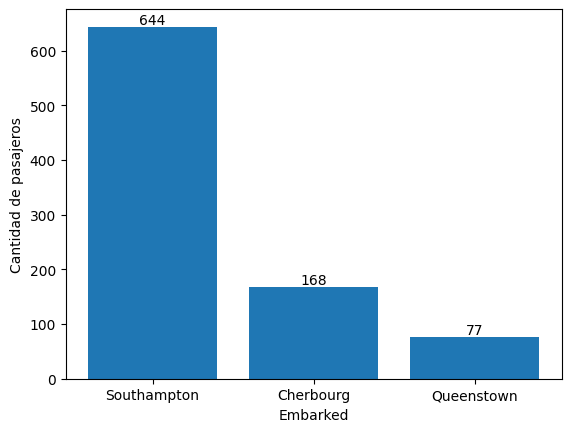

In [ ]:
# Crear el histograma
embarked_counter = df_titanic['Embarked'].value_counts()

plt.bar(embarked_counter.index, embarked_counter.values)

# Agregar etiquetas de texto encima de cada columna
for i, count in enumerate(embarked_counter.values):
    plt.text(i, count, str(count), ha='center', va='bottom')

# Agregar etiquetas y título
plt.xlabel('Embarked')
plt.ylabel('Cantidad de pasajeros')

# Mostrar el histograma
plt.show()

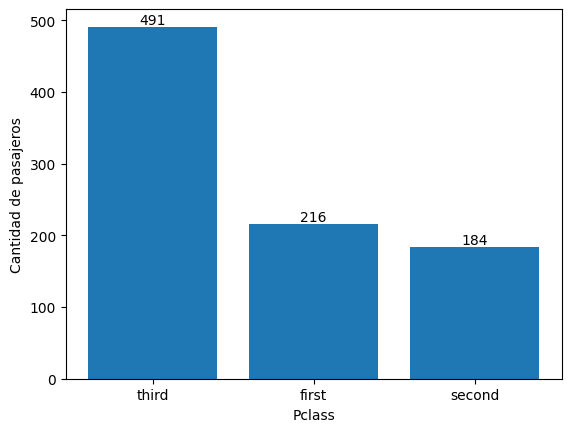

In [ ]:
# Crear el histograma
pclass_counter = df_titanic['Pclass'].value_counts()

plt.bar(pclass_counter.index, pclass_counter.values)

# Agregar etiquetas de texto encima de cada columna
for i, count in enumerate(pclass_counter.values):
    plt.text(i, count, str(count), ha='center', va='bottom')

# Agregar etiquetas y título
plt.xlabel('Pclass')
plt.ylabel('Cantidad de pasajeros')

# Mostrar el histograma
plt.show()

## Procesamiento de Datos

En el análisis anterior vimos que en el dataframe tenemos atributos categóricos (*Embarked*, *Ticket*) y atributos con valores nulos (*Age*, *Cabin*). Debido a que tanto un Árbol de Decisión como una RNA no pueden procesar información con estas características, en esta sección vamos a:
*   Ver opciones para corregir los valores nulos.
*   Convertir atributos categóricos en numéricos.
*   Eliminar atributos que no resulten útiles para aprender un patrón en los datos.

Al final de este proceso, debemos tener el conjunto de datos adecuado para entrenar un modelo de clasificación.

### Corregir valores nulos

En el dataset tenemos ejemplos para los cuales los atributos Age, Cabin y/o Embarked no tienen un valor definido.
*   Age - 177 nulos.
*   Cabin - 687 nulos.
*   Embarked - 2 nulos.

Vamos a completarlos de la siguiente forma:
*   Embarked, completar con el valor más frecuente de la columna.
*   Age, completar con el valor promedio de la columna.
*   Cabin, completar con el valor 'Unknown'.

**Link**:
* `https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html`

In [ ]:
# Obtenemos el valor más frecuente en la columna 'Embarked' (categórico)
most_common_embarked = df_titanic['Embarked'].mode()[0]
print(f"Valor más frecuente de Embarked: {most_common_embarked}")

# Obtenemos el valor promedio de la columna 'Age' (numérico)
average_age = round(df_titanic['Age'].mean())
print(f"Valor promedio de Age: {average_age}")

Valor más frecuente de Embarked: Southampton
Valor promedio de Age: 30


In [ ]:
from pandas._libs.missing import NA
# Usando el valor most_common_embarked, completamos los valores nulos en el dataframe de Titanic.
print("### 1")
display(df_original.loc[df_original['Embarked'].isna()][['Name', 'Embarked']])
print()

df_titanic['Embarked'] = df_titanic['Embarked'].fillna(most_common_embarked)

# Usando el valor average_age, completamos los valores nulos de la columna 'Age'.
# <TO-DO>
print("### 2")
display(df_original[df_original['Age'].isna()][['Name','Age']])
print()

df_titanic['Age'] = df_titanic['Age'].fillna(average_age)


# Usando el valor 'Unkown', completamos los valores nulos de la columna 'Cabin'.
# <TO-DO>
print("### 3")
display(df_original[df_original['Cabin'].isna()][['Name','Cabin']])
print()

df_titanic['Cabin'] = df_titanic['Cabin'].fillna('Unknown')

print("Verificando valores nulos:")
print(df_titanic.isna().sum())

### 1


,Name,Embarked
61,"Icard, Miss. Amelie",NaN
829,"Stone, Mrs. George Nelson (Martha Evelyn)",NaN



### 2


,Name,Age
5,"Moran, Mr. James",NaN
17,"Williams, Mr. Charles Eugene",NaN
19,"Masselmani, Mrs. Fatima",NaN
26,"Emir, Mr. Farred Chehab",NaN
28,"O'Dwyer, Miss. Ellen ""Nellie""",NaN
...,...,...
859,"Razi, Mr. Raihed",NaN
863,"Sage, Miss. Dorothy Edith ""Dolly""",NaN
868,"van Melkebeke, Mr. Philemon",NaN
878,"Laleff, Mr. Kristo",NaN



### 3


,Name,Cabin
0,"Braund, Mr. Owen Harris",NaN
2,"Heikkinen, Miss. Laina",NaN
4,"Allen, Mr. William Henry",NaN
5,"Moran, Mr. James",NaN
7,"Palsson, Master. Gosta Leonard",NaN
...,...,...
884,"Sutehall, Mr. Henry Jr",NaN
885,"Rice, Mrs. William (Margaret Norton)",NaN
886,"Montvila, Rev. Juozas",NaN
888,"Johnston, Miss. Catherine Helen ""Carrie""",NaN



Verificando valores nulos:
PassengerId    0
Survived       0
Pclass         0
Name           0
Age            0
Ticket         0
Cabin          0
Embarked       0
dtype: int64


In [ ]:
df_titanic

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked
0,1,No,third,"Braund, Mr. Owen Harris",22.0,A/5 21171,Unknown,Southampton
1,2,Yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,PC 17599,C85,Cherbourg
2,3,Yes,third,"Heikkinen, Miss. Laina",26.0,STON/O2. 3101282,Unknown,Southampton
3,4,Yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,113803,C123,Southampton
4,5,No,third,"Allen, Mr. William Henry",35.0,373450,Unknown,Southampton
...,...,...,...,...,...,...,...,...
886,887,No,second,"Montvila, Rev. Juozas",27.0,211536,Unknown,Southampton
887,888,Yes,first,"Graham, Miss. Margaret Edith",19.0,112053,B42,Southampton
888,889,No,third,"Johnston, Miss. Catherine Helen ""Carrie""",30.0,W./C. 6607,Unknown,Southampton
889,890,Yes,first,"Behr, Mr. Karl Howell",26.0,111369,C148,Cherbourg


### Representar variables categóricas

Una variable es **categórica** si toma valores de un conjunto finito de posibilidades.

Vamos a utilizar one-hot encoding para representar la columna "Embarked" y ordinal encoding para la columna "Pclass".
*   Para el primero usamos la función `get_dummies` de Pandas.
*   Para el segundo, definimos un mapeo y lo aplicamos a la columna "Pclass".

**Link**:
* `https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html`

In [ ]:
# Hacemos una copia del dataframe.
df_nuevo = df_titanic.copy()

# Aplicar encoding a la columna 'Embarked'
df_nuevo = pd.get_dummies(
    df_nuevo,
    columns=['Embarked'],
    dtype=int
)

print("Encoding aplicado...")

Encoding aplicado...


In [ ]:
df_nuevo

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked_Cherbourg,Embarked_Queenstown,Embarked_Southampton
0,1,No,third,"Braund, Mr. Owen Harris",22.0,A/5 21171,Unknown,0,0,1
1,2,Yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,PC 17599,C85,1,0,0
2,3,Yes,third,"Heikkinen, Miss. Laina",26.0,STON/O2. 3101282,Unknown,0,0,1
3,4,Yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,113803,C123,0,0,1
4,5,No,third,"Allen, Mr. William Henry",35.0,373450,Unknown,0,0,1
...,...,...,...,...,...,...,...,...,...,...
886,887,No,second,"Montvila, Rev. Juozas",27.0,211536,Unknown,0,0,1
887,888,Yes,first,"Graham, Miss. Margaret Edith",19.0,112053,B42,0,0,1
888,889,No,third,"Johnston, Miss. Catherine Helen ""Carrie""",30.0,W./C. 6607,Unknown,0,0,1
889,890,Yes,first,"Behr, Mr. Karl Howell",26.0,111369,C148,1,0,0


In [ ]:
# Aplicar encoding a la columna 'Pclass'
mapeo = {
    'first': 1,
    'second': 2,
    'third': 3
}


# Modificamos la columna 'Pclass' a partir del mapeo anterior
df_nuevo['Pclass'] = df_nuevo['Pclass'].map(mapeo)
print("Mapeo aplicado...")

Mapeo aplicado...


In [ ]:
df_nuevo

,PassengerId,Survived,Pclass,Name,Age,Ticket,Cabin,Embarked_Cherbourg,Embarked_Queenstown,Embarked_Southampton
0,1,No,3,"Braund, Mr. Owen Harris",22.0,A/5 21171,Unknown,0,0,1
1,2,Yes,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,PC 17599,C85,1,0,0
2,3,Yes,3,"Heikkinen, Miss. Laina",26.0,STON/O2. 3101282,Unknown,0,0,1
3,4,Yes,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,113803,C123,0,0,1
4,5,No,3,"Allen, Mr. William Henry",35.0,373450,Unknown,0,0,1
...,...,...,...,...,...,...,...,...,...,...
886,887,No,2,"Montvila, Rev. Juozas",27.0,211536,Unknown,0,0,1
887,888,Yes,1,"Graham, Miss. Margaret Edith",19.0,112053,B42,0,0,1
888,889,No,3,"Johnston, Miss. Catherine Helen ""Carrie""",30.0,W./C. 6607,Unknown,0,0,1
889,890,Yes,1,"Behr, Mr. Karl Howell",26.0,111369,C148,1,0,0


In [ ]:
df_nuevo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PassengerId           891 non-null    int64  
 1   Survived              891 non-null    object 
 2   Pclass                891 non-null    int64  
 3   Name                  891 non-null    object 
 4   Age                   891 non-null    float64
 5   Ticket                891 non-null    object 
 6   Cabin                 891 non-null    object 
 7   Embarked_Cherbourg    891 non-null    int64  
 8   Embarked_Queenstown   891 non-null    int64  
 9   Embarked_Southampton  891 non-null    int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 69.7+ KB


### Eliminar atributos del dataframe

In [ ]:
# Nombres de las columnas a eliminar (entre comillas simples)
# <TO-DO>
columnas_a_eliminar = ['Ticket', 'Cabin']

# Hacemos una copia del último dataframe
df_util = df_nuevo.copy()

# Eliminar las columnas seleccionadas
# <TO-DO>
df_util = df_util.drop(columns=columnas_a_eliminar)

print("Cantidad de ejemplos: {}\nCantidad de columnas: {}".format(df_util.shape[0], df_util.shape[1]))

Cantidad de ejemplos: 891
Cantidad de columnas: 8


In [ ]:
df_util

,PassengerId,Survived,Pclass,Name,Age,Embarked_Cherbourg,Embarked_Queenstown,Embarked_Southampton
0,1,No,3,"Braund, Mr. Owen Harris",22.0,0,0,1
1,2,Yes,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,0
2,3,Yes,3,"Heikkinen, Miss. Laina",26.0,0,0,1
3,4,Yes,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,0,0,1
4,5,No,3,"Allen, Mr. William Henry",35.0,0,0,1
...,...,...,...,...,...,...,...,...
886,887,No,2,"Montvila, Rev. Juozas",27.0,0,0,1
887,888,Yes,1,"Graham, Miss. Margaret Edith",19.0,0,0,1
888,889,No,3,"Johnston, Miss. Catherine Helen ""Carrie""",30.0,0,0,1
889,890,Yes,1,"Behr, Mr. Karl Howell",26.0,1,0,0
